# ADME_ML — results

Reads the per-endpoint metrics pickles and plots them. Nothing is refitted here, so the notebook is cheap to re-run.

- **RF dir** `params.METRICS_PKL_RF_DIR` — 6 arms per endpoint
- **chemprop dir** `params.METRICS_PKL_CP_DIR` — 3 arms per endpoint

Both figures take `metric=` (`r2` squared Pearson, or `r2det` the calibration-sensitive selection metric) and `dpi=` (the save switch: `None` writes no file).

In [1]:
%load_ext autoreload
%autoreload 2

## repo root on sys.path, so `python.` imports whether the kernel starts in vignettes/ or in the root
import os, sys
sys.path[:0] = [os.path.abspath('..'), os.path.abspath('.')]

## imports — pyplot for show(), the config reader, and the two figure helpers
import matplotlib.pyplot as plt
from python.ADME_build_ML import PARAMS       # importing it also chdirs to the repo root
import python.functions as fn

## params — every YAML key becomes an attribute (METRICS_PKL_*, ADME_ENDPOINTS, webapp, SERAC_C)
params = PARAMS('config/config.yaml').load_params()

> loaded 20 params from config/config.yaml


## 1. RF only

> saved output/figures/bar_summary_RF_r2.png (dpi=150)
RF arms, r2
              n  ext_->_internal  internal_cv  augmented_cv
solubility  120            0.577        0.680         0.742
logd        317            0.620        0.818         0.813
mdck        107            0.402        0.483         0.445
mdck_inh    146            0.585        0.684         0.695
hlm         324            0.170        0.595         0.505
mlm         324            0.287        0.666         0.549
rlm          39            0.176        0.116         0.303
caco2        95            0.529        0.763         0.539
ppb          69            0.087        0.463         0.525


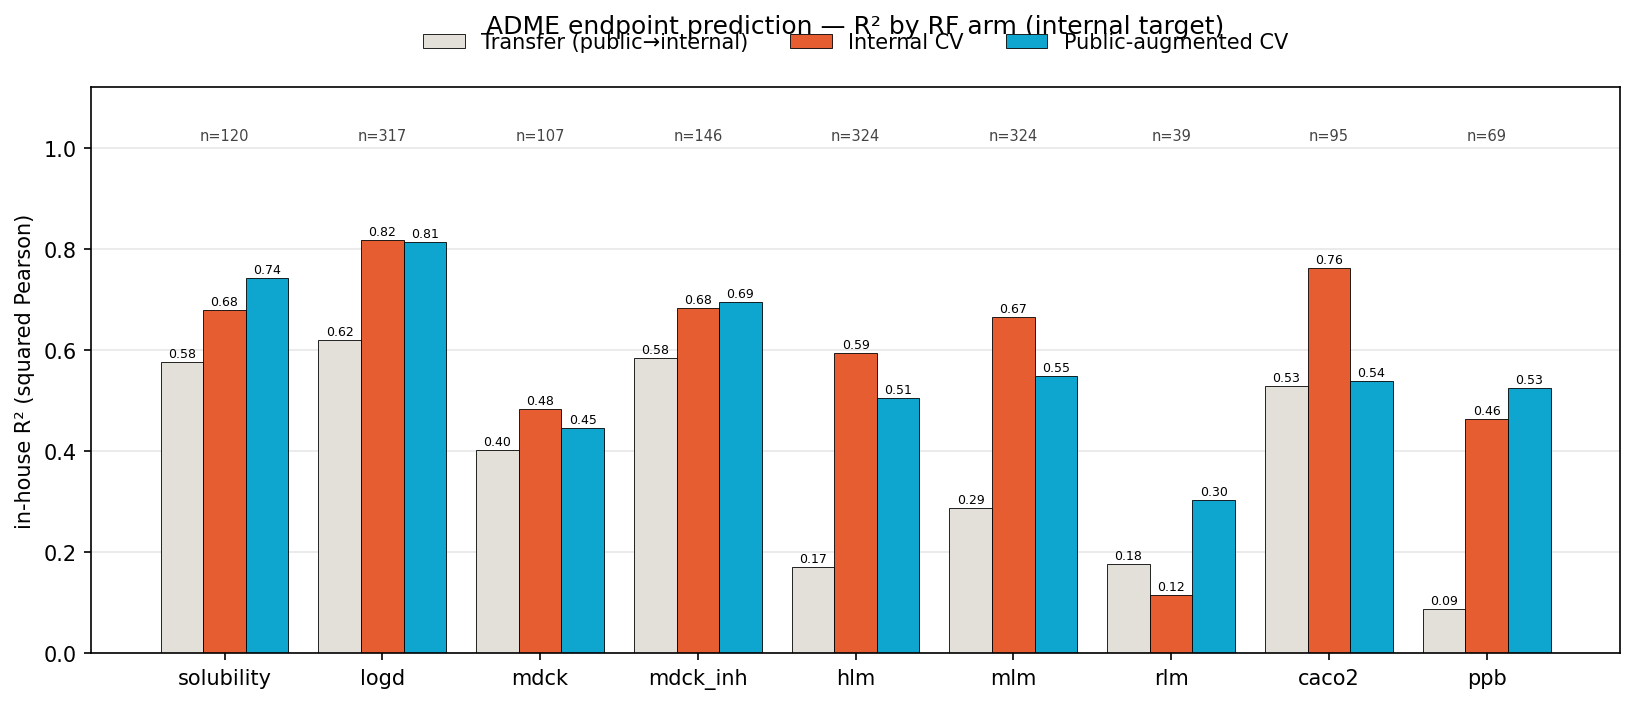

In [8]:
## RF only — transfer (public->internal) / internal CV / public-augmented CV, per endpoint
# dpi is the SAVE SWITCH: None shows the figure and writes no file; set e.g. dpi=150 to export a png
fig, rf_df = fn.plot_bar_summary_RF_all_endpoints(
    'output/results/20260909_metrics_rf', params, metric='r2', out_png=None, dpi=150)
# plt.show()

## 2. Best model per endpoint — RF vs chemprop vs near-shell

> saved output/figures/bar_summary_RF_CP_r2det.png (dpi=150)
winner per arm, r2det (no internal compound in any transfer training set)
              n  ext_->_internal ext_->_internal_by  internal_cv internal_cv_by  augmented_cv augmented_cv_by           note
solubility  120            0.422                 RF        0.680             RF         0.754        chemprop           all8
logd        317            0.476           chemprop        0.816             RF         0.840        chemprop       sol_lipo
mdck        107           -1.506           chemprop        0.482             RF         0.539      near-shell  dist060_agree
mdck_inh    146           -0.121                 RF        0.684             RF         0.694              RF     all public
hlm         324           -0.851           chemprop        0.583             RF         0.603        chemprop      clearance
mlm         324           -0.191           chemprop        0.651             RF         0.657        chemprop      

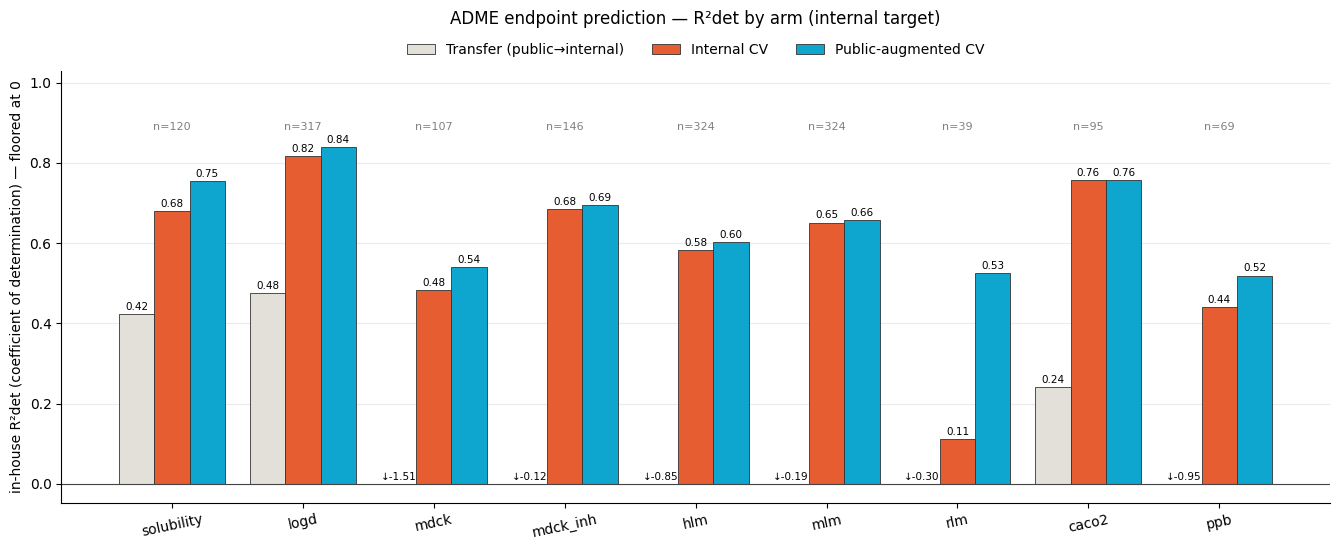

In [9]:
## best of RF vs chemprop (near-shell joins the augmented arm) — same three arms
# the bar answers "how well can we predict this endpoint", not "how good is one model"
fig, best_df = fn.plot_bar_summary_RF_CP_all_endpoints('output/results/20260909_metrics_rf', 'output/results/20260909_metrics_cp', params, metric='r2det',out_png=None, dpi=150)
# plt.show()